In [1]:
import numpy
import scipy
print(numpy.__version__, scipy.__version__)

1.26.4 1.13.1


### Standardize the versions of Numpy

In [3]:
%pip install numpy==1.26.4 --force-reinstall

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.4.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.



  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   ---------------------------------------- 0.1/15.5 MB 656.4 kB/s eta 0:00:24
   ---------------------------------------- 0.1/15.5 MB 657.6 kB/s eta 0:00:24
   ---------------------------------------- 0.1/15.5 MB 525.1 kB/s eta 0:00:30
    --------------------------------------- 0.2/15.5 MB 908.0 kB/s eta 0:00:17
    --------------------------------------- 0.2/15.5 MB 831.5 kB/s eta 0:00:19
   - -------------------------------------- 0.4/15.5 MB 1.3 MB/s eta 0:00:12
   - -------------------------------------- 0.5/15.5 MB 1.3 MB/s eta 0:00:12
   - -------------------------------------- 0.6/15.5 MB 1.4 MB/s eta 0:00:11
   -- ------------------------------------- 0.8/15.5 MB 1.9 MB/s eta 0:00:08
   -- ------------------------------------- 0.9/15.5 MB 1.8 MB/s eta 0:00:09
   -- --

## Import library functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import random
import time

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

## Public baseplate

In [2]:
def load_workload_instance(file_path):
    """
    Official lecturer‑provided dataset loader
    Return n, m, utilities, demands, capacities
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()

    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2

    utilities = np.array([float(x) for x in tokens[idx: idx + n]])
    idx += n

    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    capacities = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, utilities, demands, capacities


def is_feasible(solution, demands, capacities):
    """
    Check binary solution satisfies resource constraints.
    Add epsilon 1e‑9 for floating‑point numerical tolerance.
    """
    res_used = demands @ solution
    return np.all(res_used <= capacities + 1e-9)


# ---------------- Variant A : Penalty‑based constraint handling (Part 1) ----------------
def fitness_penalty(solution, utilities, demands, capacities, penalty_weight=10000):
    """
    Variant‑A Penalty function
    Feasible → raw total utility
    Infeasible → subtract penalty proportional to resource overshoot
    The input solution vector is NOT modified.
    """
    total_u = np.sum(utilities * solution)
    if is_feasible(solution, demands, capacities):
        return total_u
    overshoot = np.maximum((demands @ solution) - capacities, 0.0)
    return total_u - penalty_weight * np.sum(overshoot)


# ---------------- Variant B : Repair‑based constraint handling (Part2 & Part3) ----------------
def repair_solution(sol, demands, capacities, utilities):
    """
    Variant‑B Repair strategy:
    For infeasible solution, remove selected models ordered by ascending utility‑density (remove lowest‑value‑per‑resource first), until feasible.
    Return repaired feasible binary solution copy.
    """
    sol = sol.copy().astype(int)
    n = len(sol)
    density = np.zeros(n)
    mask = sol == 1
    density[mask] = utilities[mask] / (demands[:, mask].sum(axis=0) + 1e-9)

    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]

    for idx in selected_idx:
        if is_feasible(sol, demands, capacities):
            break
        sol[idx] = 0
    return sol


def fitness_repair(sol, utilities, demands, capacities):
    """
    Fitness for Variant‑B repair approach: repair solution first, return total utility of repaired feasible solution.
    """
    fixed_sol = repair_solution(sol, demands, capacities, utilities)
    if is_feasible(fixed_sol, demands, capacities):
        return float(utilities @ fixed_sol)
    return 0.0

## GA algorithm for Variant B (Repair strategy)

In [3]:
def ga_optimize(n, m, utilities, demands, capacities,
                pop_size=80,
                max_iter=200,
                cross_prob=0.85,
                mut_prob=0.03,
                seed=42):
    random.seed(seed)
    np.random.seed(seed)
    # Initialize population: randomly set to 0 or 1, and then fully repair (Variant B)
    pop = []
    for _ in range(pop_size):
        s = np.random.randint(0,2,size=n)
        s = repair_solution(s, demands, capacities, utilities)
        pop.append(s)
    pop = np.array(pop)
    best_fit_hist = []
    best_sol = None
    best_fit = -1
    
    for it in range(max_iter):
        # evaluation using variant B of fitness_repair
        fits = np.array([fitness_repair(s, utilities, demands, capacities) for s in pop])
        current_best_idx = np.argmax(fits)
        if fits[current_best_idx] > best_fit:
            best_fit = fits[current_best_idx]
            best_sol = pop[current_best_idx].copy()
        best_fit_hist.append(best_fit)
        
        # ---------- Option: Roulette wheel selection ----------
        fit_norm = fits - fits.min() + 1e-6
        prob = fit_norm / fit_norm.sum()
        new_pop = []
        for _ in range(pop_size):
            pick_idx = np.random.choice(pop_size, p=prob)
            new_pop.append(pop[pick_idx].copy())
        new_pop = np.array(new_pop)
        
        # ---------- Single-point crossover ----------
        for i in range(0, pop_size, 2):
            if np.random.rand() < cross_prob:
                p1 = new_pop[i]
                p2 = new_pop[i+1]
                cut = np.random.randint(1, n-1)
                c1 = np.concatenate([p1[:cut], p2[cut:]])
                c2 = np.concatenate([p2[:cut], p1[cut:]])
                # Offspring repair! Variant B core
                c1 = repair_solution(c1, demands, capacities, utilities)
                c2 = repair_solution(c2, demands, capacities, utilities)
                new_pop[i] = c1
                new_pop[i+1] = c2
        
        # ---------- Mutation: Bit inversion ----------
        for i in range(pop_size):
            for j in range(n):
                if np.random.rand() < mut_prob:
                    new_pop[i,j] = 1 - new_pop[i,j]
            # Repair after mutation
            new_pop[i] = repair_solution(new_pop[i], demands, capacities, utilities)
        pop = new_pop
    return best_sol, best_fit, best_fit_hist

## Run experiment: Variant B

In [5]:
def run_ga_repeat(n, m, utilities, demands, capacities, repeat=30, **ga_kwargs):
    """
    Run GA multiple times independently to collect statistical results.
    **ga_kwargs passes hyperparameters for ga_optimize.
    """
    all_best_fit = []
    all_history = []
    for run_id in range(repeat):
        # Use different seed for each independent replication
        sol, fit, hist = ga_optimize(n, m, utilities, demands, capacities, seed=run_id, **ga_kwargs)
        all_best_fit.append(fit)
        all_history.append(hist)
    return np.array(all_best_fit), np.array(all_history)

# ===================== Run Experiment =====================
# Load dataset
n_inst, m_inst, utilities_inst, demands_inst, capacities_inst = load_workload_instance("data/multi_resource_n90_m5.txt")

# Run 30 independent experiments
repeat_times = 30
resB_fits, resB_hists = run_ga_repeat(n_inst, m_inst, utilities_inst, demands_inst, capacities_inst, repeat=repeat_times)


# Print statistical metrics
print(f"Variant B (Repair) {repeat_times} independent runs:")
print(f"Mean = {np.mean(resB_fits):.2f}")
print(f"Std = {np.std(resB_fits):.2f}")
print(f"Max = {np.max(resB_fits):.2f}")
print(f"Min = {np.min(resB_fits):.2f}")

# Save results for comparison and statistical test
np.save("variantB_fits.npy", resB_fits)
np.save("variantB_history.npy", resB_hists)

Variant B (Repair) 30 independent runs:
Mean = 10665.30
Std = 80.82
Max = 10817.00
Min = 10528.00


## Load Experimental Results for Variant A and Variant B

In [6]:
# Load data of B
resB_fits = np.load("variantB_fits.npy")
resB_hists = np.load("variantB_history.npy")

# Load data of A
resA_fits = np.load("variantA_fits.npy")
resA_hists = np.load("variantA_history.npy")

print(resB_fits)
print(resB_fits.shape) 


[10817. 10731. 10528. 10673. 10716. 10710. 10746. 10729. 10807. 10618.
 10555. 10632. 10696. 10636. 10544. 10722. 10600. 10682. 10583. 10663.
 10605. 10817. 10610. 10676. 10647. 10790. 10679. 10600. 10552. 10595.]
(30,)


## Visualization: Convergence Curve and Boxplot Comparison

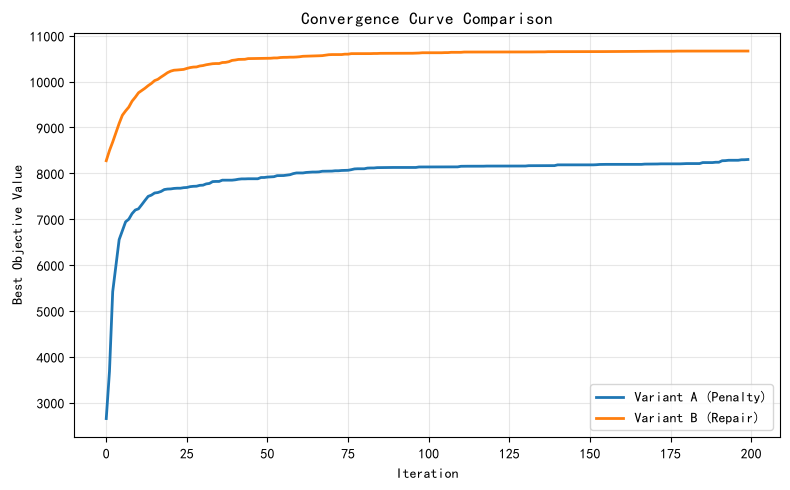

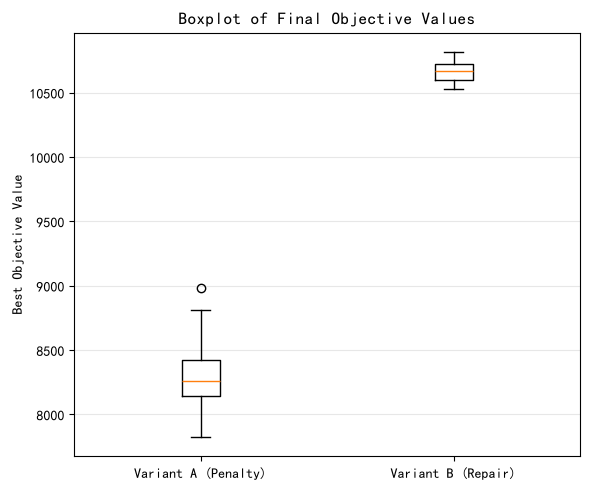

In [8]:
# ---------------------- Load Data ----------------------
# Load Variant B
resB_fits = np.load("variantB_fits.npy")
resB_hists = np.load("variantB_history.npy")

# Load Variant A
resA_fits = np.load("variantA_fits.npy")
resA_hists = np.load("variantA_history.npy")

# Compute mean convergence curve across 30 runs
mean_curve_B = np.mean(resB_hists, axis=0)
mean_curve_A = np.mean(resA_hists, axis=0)

# ---------------------- Figure 1: Convergence Curve ----------------------
plt.figure(figsize=(8, 5))
plt.plot(mean_curve_A, label="Variant A (Penalty)", linewidth=2)
plt.plot(mean_curve_B, label="Variant B (Repair)", linewidth=2)

plt.xlabel("Iteration")
plt.ylabel("Best Objective Value")
plt.title("Convergence Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("convergence_compare.png", dpi=300)
plt.show()

# ---------------------- Figure 2: Boxplot ----------------------
plt.figure(figsize=(6, 5))
data = [resA_fits, resB_fits]
labels = ["Variant A (Penalty)", "Variant B (Repair)"]

plt.boxplot(data, tick_labels=labels)
plt.ylabel("Best Objective Value")
plt.title("Boxplot of Final Objective Values")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("boxplot_compare.png", dpi=300)
plt.show()


## Statistical Summary

In [9]:
# statistics
def stat_summary(arr, name):
    print(f"{name} | Mean: {np.mean(arr):.2f} | Std: {np.std(arr):.2f} | Max: {np.max(arr):.2f} | Min: {np.min(arr):.2f}")

stat_summary(resA_fits, "Variant A (Penalty)")
stat_summary(resB_fits, "Variant B (Repair)")

Variant A (Penalty) | Mean: 8300.67 | Std: 241.21 | Max: 8983.00 | Min: 7824.00
Variant B (Repair) | Mean: 10665.30 | Std: 80.82 | Max: 10817.00 | Min: 10528.00
